# Week 11 Jupyter Notebook – DBSCAN and Hierarchical Clustering
## Comparing Different Ways to Group Borrowers

### Project Overview

For Week 11, I am continuing the unsupervised analysis from Week 10. I wanted to see whether density-based clustering and hierarchical clustering find similar borrower groups or identify patterns that K-Means may miss. Loan status is excluded from the clustering inputs and used only afterward to describe the groups.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, silhouette_score, adjusted_rand_score)
pd.set_option('display.max_columns', None)

from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

In [ ]:
# In Colab, upload credit_risk_dataset 2.csv if it is not already available.
try:
    df = pd.read_csv('credit_risk_dataset 2.csv')
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))
print('Dataset shape:', df.shape)
display(df.head())


Saving credit_risk_dataset 2.csv to credit_risk_dataset 2.csv
Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
target = 'loan_status'
continuous_features = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
categorical_features = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
data = df[continuous_features + categorical_features + [target]].dropna().copy()
print('Rows after removing missing values:', len(data))
print('Default rate:', round(data[target].mean(), 4))
X = data[continuous_features + categorical_features]
y = data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('Training observations:', len(X_train), 'Testing observations:', len(X_test))


Rows after removing missing values: 28638
Default rate: 0.2166
Training observations: 22910 Testing observations: 5728


## Data Preprocessing

I used the same standardized continuous variables and encoded categorical variables as Week 10. I again used a reproducible sample so the clustering methods could be compared on the same observations.

In [ ]:
# I am using a reproducible sample because silhouette and hierarchical clustering can be expensive on all 28,000+ complete observations.
cluster_data = data.sample(n=min(3000,len(data)),random_state=42).copy()
cluster_X = cluster_data[continuous_features + categorical_features]
cluster_y = cluster_data[target]
cluster_preprocessor = ColumnTransformer([('continuous',StandardScaler(),continuous_features),('categorical',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False),categorical_features)])
cluster_matrix = cluster_preprocessor.fit_transform(cluster_X)
print('Clustering observations:',len(cluster_data))
print('Encoded predictors:',cluster_matrix.shape[1])


Clustering observations: 3000
Encoded predictors: 22


## DBSCAN

DBSCAN groups observations in dense regions and labels observations outside those regions as noise (-1). I compared different neighborhood radii (eps) and minimum sample counts. Very small eps values can label almost everything as noise, while very large values may merge borrowers into one group.

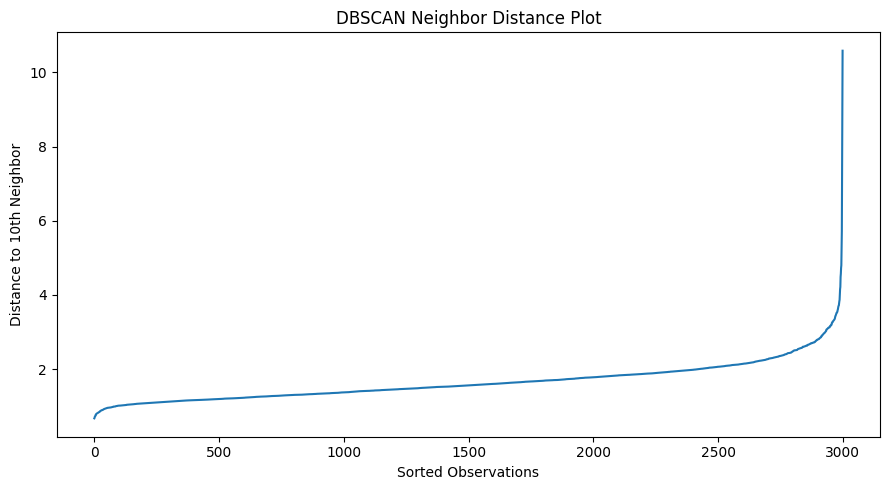

In [ ]:
neighbors=NearestNeighbors(n_neighbors=10).fit(cluster_matrix)
distances,_=neighbors.kneighbors(cluster_matrix)
plt.figure(figsize=(9,5));plt.plot(np.sort(distances[:,-1]));plt.xlabel('Sorted Observations');plt.ylabel('Distance to 10th Neighbor');plt.title('DBSCAN Neighbor Distance Plot');plt.tight_layout();plt.show()

In [ ]:
db_results=[]
for eps in [2.0,2.5,3.0,3.5,4.0,5.0]:
    for min_samples in [5,10]:
        labels=DBSCAN(eps=eps,min_samples=min_samples,n_jobs=-1).fit_predict(cluster_matrix)
        n_clusters=len(set(labels)-{-1})
        noise_rate=np.mean(labels==-1)
        valid=labels!=-1
        score=np.nan
        if n_clusters>=2 and valid.sum()>n_clusters:
            score=silhouette_score(cluster_matrix[valid],labels[valid],sample_size=min(1000,int(valid.sum())),random_state=42)
        db_results.append({'eps':eps,'min_samples':min_samples,'Clusters':n_clusters,'Noise Rate':noise_rate,'Silhouette (non-noise)':score})
db_df=pd.DataFrame(db_results)
display(db_df.round(4))

,eps,min_samples,Clusters,Noise Rate,Silhouette (non-noise)
0,2.0,5,2,0.0667,0.4565
1,2.0,10,1,0.0897,NaN
2,2.5,5,2,0.0167,0.3841
3,2.5,10,1,0.0283,NaN
4,3.0,5,1,0.0060,NaN
5,3.0,10,1,0.0073,NaN
6,3.5,5,1,0.0020,NaN
7,3.5,10,1,0.0030,NaN
8,4.0,5,1,0.0010,NaN
9,4.0,10,1,0.0020,NaN


## DBSCAN Results

Silhouette scores are only defined when at least two clusters exist. I also considered the percentage of observations labeled as noise so that a result with almost no clustered borrowers would not be treated as a strong solution.

In [ ]:
valid_db=db_df[(db_df['Clusters']>=2)&(db_df['Noise Rate']<0.80)&db_df['Silhouette (non-noise)'].notna()]
if len(valid_db):
    best_db=valid_db.sort_values('Silhouette (non-noise)',ascending=False).iloc[0]
else:
    best_db=db_df.sort_values(['Noise Rate','Clusters'],ascending=[True,False]).iloc[0]
db_labels=DBSCAN(eps=float(best_db['eps']),min_samples=int(best_db['min_samples']),n_jobs=-1).fit_predict(cluster_matrix)
cluster_data['DBSCAN Cluster']=db_labels
print('Selected DBSCAN settings:',best_db[['eps','min_samples','Clusters','Noise Rate']].to_dict())
display(cluster_data.groupby('DBSCAN Cluster')['loan_status'].agg(['count','mean']).rename(columns={'mean':'Default Rate'}).round(4))

Selected DBSCAN settings: {'eps': 2.0, 'min_samples': 5.0, 'Clusters': 2.0, 'Noise Rate': 0.06666666666666667}


,count,Default Rate
DBSCAN Cluster,,
-1,200,0.3850
0,2795,0.2068
1,5,0.0000


The selected DBSCAN model used eps = 2.0 and min_samples = 5. It identified two clusters and classified 6.67% of observations as noise. The silhouette score for observations assigned to clusters was 0.4565, which was higher than the Week 10 K-Means result.

However, one of the clusters contained only five borrowers, while the other contained 2,795. This means that the silhouette score should be interpreted carefully because the model did not identify two similarly sized groups.

The 200 observations labeled as noise had a default rate of 38.5%, compared with 20.68% in the largest cluster. This was an interesting result because the unusual observations had a noticeably higher observed default rate. However, DBSCAN identifies observations based on density rather than default status, so being labeled as noise does not necessarily mean that a borrower will default.

## Hierarchical Agglomerative Clustering

Hierarchical clustering starts with individual observations and merges the closest groups. I used Ward linkage, which works with Euclidean distance, and compared two through six clusters using silhouette scores.

In [ ]:
hier_results=[]
for k in range(2,7):
    labels=AgglomerativeClustering(n_clusters=k,linkage='ward').fit_predict(cluster_matrix)
    hier_results.append({'Clusters':k,'Silhouette':silhouette_score(cluster_matrix,labels,sample_size=1500,random_state=42)})
hier_df=pd.DataFrame(hier_results)
display(hier_df.round(4))
best_hier_k=int(hier_df.loc[hier_df['Silhouette'].idxmax(),'Clusters'])
hier_labels=AgglomerativeClustering(n_clusters=best_hier_k,linkage='ward').fit_predict(cluster_matrix)
cluster_data['Hierarchical Cluster']=hier_labels
print('Best hierarchical cluster count:',best_hier_k)
display(cluster_data.groupby('Hierarchical Cluster')['loan_status'].agg(['count','mean']).rename(columns={'mean':'Default Rate'}).round(4))

,Clusters,Silhouette
0,2,0.1674
1,3,0.1747
2,4,0.1046
3,5,0.1168
4,6,0.1075


Best hierarchical cluster count: 3


,count,Default Rate
Hierarchical Cluster,,
0,1905,0.1648
1,440,0.1023
2,655,0.4519


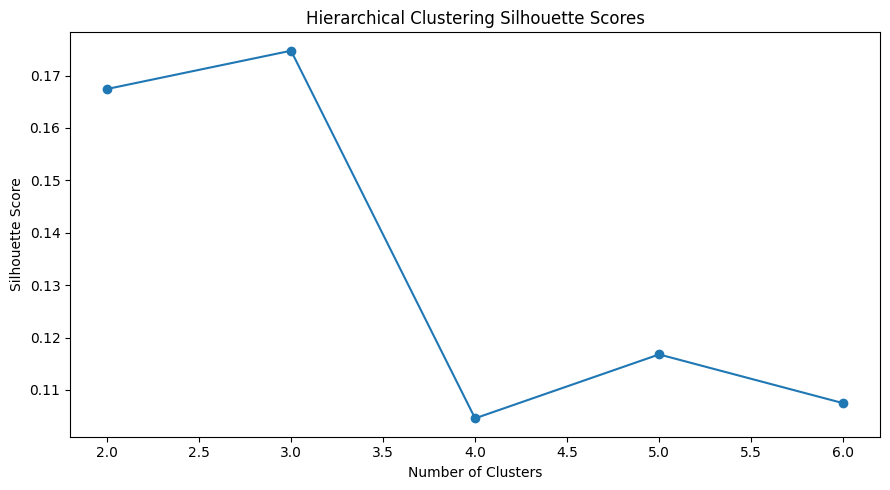

In [ ]:
plt.figure(figsize=(9,5));plt.plot(hier_df['Clusters'],hier_df['Silhouette'],marker='o');plt.xlabel('Number of Clusters');plt.ylabel('Silhouette Score');plt.title('Hierarchical Clustering Silhouette Scores');plt.tight_layout();plt.show()

The highest hierarchical clustering silhouette score was 0.1747 with three clusters. Although the score was relatively low, the resulting groups showed more noticeable differences in default rates than the Week 10 K-Means clusters.

Cluster 0 contained 1,905 borrowers with a default rate of 16.48%, while Cluster 1 contained 440 borrowers with a default rate of 10.23%. Cluster 2 contained 655 borrowers and had a much higher default rate of 45.19%.

I did not expect the hierarchical clusters to show such a large difference in default rates given the relatively low silhouette score. This suggests that groups do not need to be strongly separated geometrically to show differences in observed credit risk. However, these differences are descriptive and do not establish that the clustering method can accurately predict defaults.

## Comparing Clustering Results

I projected the observations into two principal components to visualize the groups. This is only a two-dimensional view of the data, not the full space used by the models. I also compared the two clustering assignments with adjusted Rand index for observations DBSCAN did not mark as noise.

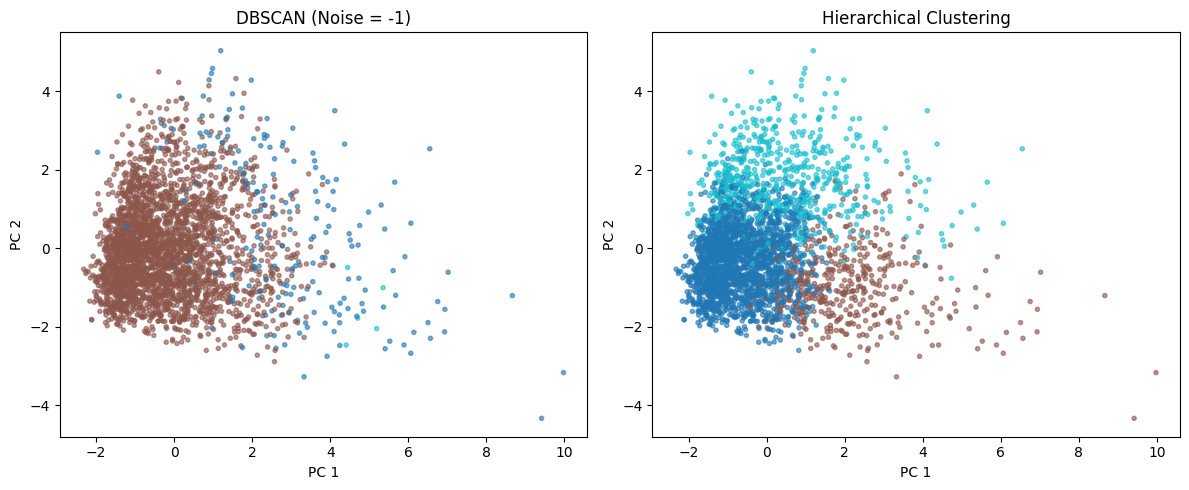

Adjusted Rand index: 0.1476


In [ ]:
points=PCA(n_components=2,random_state=42).fit_transform(cluster_matrix)
fig,axes=plt.subplots(1,2,figsize=(12,5))
axes[0].scatter(points[:,0],points[:,1],c=db_labels,s=9,alpha=0.6,cmap='tab10');axes[0].set_title('DBSCAN (Noise = -1)')
axes[1].scatter(points[:,0],points[:,1],c=hier_labels,s=9,alpha=0.6,cmap='tab10');axes[1].set_title('Hierarchical Clustering')
for ax in axes:ax.set_xlabel('PC 1');ax.set_ylabel('PC 2')
plt.tight_layout();plt.show()
print('Adjusted Rand index:',round(adjusted_rand_score(db_labels,hier_labels),4))

The adjusted Rand index between the DBSCAN and hierarchical clustering assignments was 0.1476, indicating relatively low agreement between the two methods. This suggests that the algorithms identified different structures in the borrower data.

The PCA visualizations also provided a simplified view of the clusters, but they only represented two dimensions of the original feature space. I therefore relied on the silhouette scores, cluster sizes, noise rates, and observed default rates rather than the graphs alone when evaluating the results.

## Conclusions

I compared DBSCAN and hierarchical clustering to see whether they identified borrower groups that K-Means may have missed. DBSCAN produced a silhouette score of 0.4565 for its non-noise observations, but one of its two clusters contained only five borrowers. This limited how useful the clustering solution was for interpreting broader borrower groups.

One interesting result was that the observations labeled as noise had a 38.5% default rate, compared with 20.68% in the largest DBSCAN cluster. Hierarchical clustering also identified a group with a substantially higher default rate of 45.19%, compared with 10.23% and 16.48% in the other two groups.

Although hierarchical clustering had a lower silhouette score of 0.1747, it produced groups with more meaningful differences in observed default rates. This was somewhat unexpected and showed that geometric separation and credit-risk differences are not necessarily the same thing.

Overall, hierarchical clustering appeared more useful for exploring possible borrower risk segments, while DBSCAN was useful for identifying unusual observations. Both methods were applied to a sample of 3,000 borrowers, and neither used loan status to construct the groups. The results are descriptive rather than evidence of predictive performance and would need further validation before being used in a banking risk assessment.

In [ ]:
print('DBSCAN clusters:',len(set(db_labels)-{-1}))
print('DBSCAN noise rate:',round(np.mean(db_labels==-1),4))
print('Hierarchical clusters:',best_hier_k)
print('Hierarchical silhouette:',round(hier_df['Silhouette'].max(),4))

DBSCAN clusters: 2
DBSCAN noise rate: 0.0667
Hierarchical clusters: 3
Hierarchical silhouette: 0.1747
